![Banner](../../../../Images/Banner/07_remote_sensing/09_06_banner_rs_lidar.png)


# Forest Structure and Individual Trees from LiDAR

Forests are where LiDAR shows its greatest advantage over passive imagery: pulses pass through gaps in the canopy, so one survey records canopy height, cover, the vertical distribution of foliage and the ground beneath. This notebook turns the Madison, Mississippi, point cloud into the two kinds of forest information used in practice: **area-based** metrics on a grid or on field plots, and **individual trees** with their heights and crowns. A denser 2020 survey from Ithaca, New York, shows how point density changes the results.


## Overview

### Why LiDAR for forests

Canopy height is the strongest single predictor of timber volume and aboveground biomass, and LiDAR measures it directly, to within about a metre for dominant trees. Optical and radar sensors only infer it. National forest inventories in the Nordic countries, forest agencies in North America and carbon projects worldwide use airborne LiDAR to map volume, basal area, biomass, site quality, fuel loads for fire models and habitat structure for wildlife.

### Height normalisation

Raw point elevations mix terrain and vegetation. Subtracting the DEM elevation interpolated at each point's position gives its **height above ground**:

$$h_i = z_i - \text{DEM}(x_i, y_i).$$

Every forest metric is computed from these heights; errors in the ground classification therefore propagate directly into canopy heights.

### The area-based approach (ABA)

The ABA (Næsset 2002) summarises the heights of all returns in a cell or plot with a set of **metrics** and links them to field measurements with a regression model:

| Metric | Definition | Relates to |
|---|---|---|
| $h_{\max}$, $h_{\text{mean}}$, $h_{\text{sd}}$ | Maximum, mean and standard deviation of heights | Top height, average height, layering |
| Percentiles $p_{25}, p_{50}, p_{75}, p_{95}$ | Height below which that share of returns lies | Volume and biomass ($p_{95}$ is close to dominant height) |
| Canopy cover | Share of first returns above a height threshold (often 2 m) | Crown closure, light interception |
| Coefficient of variation | $h_{\text{sd}} / h_{\text{mean}}$ | Structural complexity |
| Foliage height diversity (FHD) | Shannon diversity $-\sum p_k \ln p_k$ of returns in height layers (MacArthur and MacArthur 1961) | Vertical layering, bird habitat |
| Effective LAI | $-\ln(P_{\text{gap}}) / k$ from the gap fraction (Beer-Lambert law) | Leaf area |
| Canopy relief ratio | $(h_{\text{mean}} - h_{\min}) / (h_{\max} - h_{\min})$ | Shape of the canopy profile |

Field plots (typically 200 to 900 m²) are measured on the ground, the same metrics are computed for the LiDAR points inside each plot, a model (linear regression on log-transformed metrics, random forest, etc.) is fitted, and the model is applied to every grid cell of the same size.

### Vertical profiles

The share of returns in each height layer, corrected for the light that never reached lower layers, gives a **leaf area density** profile (MacArthur and Horn 1969):

$$\text{LAD}_k = \frac{1}{k\,\Delta z}\ln\frac{P_{\text{gap}}(z_k)}{P_{\text{gap}}(z_{k+1})},$$

where $P_{\text{gap}}(z)$ is the fraction of returns below height $z$ and $k \approx 0.5$ is the extinction coefficient.

### Individual tree detection (ITD)

With enough points per crown (roughly 5 or more per m²), individual trees can be found:

1. **Treetops** are local maxima of the CHM. The search window should scale with tree height, because tall trees have wide crowns; a fixed window either merges small trees or splits large crowns.
2. **Crowns** grow outward from the treetops with a marker-controlled **watershed** on the inverted CHM, stopping where crowns meet or the canopy drops below a minimum height.
3. **Per-tree attributes**: height, crown area and diameter, and through allometric equations stem diameter, volume and biomass.

Point-based methods assign points to trees directly in 3D and avoid the smoothing of a raster CHM. ITD works best for conifers with distinct apexes; broad, interlocking deciduous crowns are often merged or split.


## Forest Analysis with GeoLattice


### Learning objectives

1. Normalise point heights with a DEM and relabel vegetation by height.
2. Build canopy height models and canopy cover maps and understand pit filling and cell size.
3. Compute area-based metrics on a grid and for circular field plots.
4. Describe vertical structure with height profiles, leaf area density and foliage height diversity.
5. Detect treetops with variable and fixed windows, segment crowns and check allometry.
6. Segment trees directly in the point cloud and extract the points of individual trees.
7. Assess how point density changes canopy metrics and tree detection.


### Data

| File | Content |
|---|---|
| `madison_utm.laz` | Madison, Mississippi: airborne LiDAR in UTM zone 15N metres, about 1.7 points/m², leaf-on, mixed pine and hardwood forest, written by the fundamentals notebook |
| `Ithaca/u_3780069650.las` | One USGS 3DEP 2020 tile from Ithaca, New York, about 6.5 points/m², with ground classified |


### Contents

1. Setup
2. Height normalisation and vegetation classes
3. Canopy height model and canopy cover
4. Area-based metrics on a grid
5. Vertical structure
6. Metrics for field plots
7. Treetop detection
8. Crown segmentation and allometry
9. Point-based tree segmentation
10. Point clouds of individual trees
11. Effect of point density
12. Exporting the products
13. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

import time  # timing
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import rasterio  # raster I/O
import matplotlib.pyplot as plt  # figures

import geolattice.rsense as rs  # GeoLattice remote sensing

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages
plt.rcParams.update({"figure.dpi": 110})  # figure resolution
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))  # version and array backend

geolattice.rsense 0.3.35 | backend: cpu


In [2]:
from pathlib import Path  # file paths

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_06_lidar/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_06_lidar"), Path("../../../../Data/08_remote_sensing/08_06_lidar"))
             if p.is_dir()), None)
if DATA is None:  # neither location exists
    # stop with a clear message
    raise FileNotFoundError("Run the notebook from its own folder or from the GeoLattice repository root.")
OUT = DATA.parent / "outputs"  # folder for the products this notebook writes
OUT.mkdir(exist_ok=True)  # create it if needed

MADISON_UTM = DATA / "madison_utm.laz"  # metric Madison cloud from the fundamentals notebook
if not MADISON_UTM.exists():  # not written yet: build it from the COPC file
    ft = rs.lidar.read_las(DATA / "madison.copc.laz")  # feet, state plane
    xy = rs.lidar.reproject(ft, 32615)  # x and y to UTM 15N
    # write the metric cloud (z feet -> metres)
    rs.lidar.write_las(rs.PointCloud(xy.x, xy.y, np.asarray(ft.z) * 0.3048006096, dict(xy.attrs), 32615),
                       MADISON_UTM)  # with z converted to metres
ITHACA_TILE = DATA / "Ithaca" / "u_3780069650.las"  # a 2020 tile with forested valley walls

## Height normalisation and vegetation classes

The analysis uses a 1 km x 1 km block of the Madison survey. The DEM comes from the producer's ground points (class 2); `rs.lidar.normalize_heights` adds a `height` field to every point by bilinear interpolation of the DEM.

The fundamentals notebook showed that this producer used the vegetation codes 3 and 4 by return number, not by height. `rs.lidar.classify_vegetation` relabels vegetation by height above ground with the ASPRS convention: low (3) 0.5 to 2 m, medium (4) 2 to 5 m and high (5) above 5 m.


In [3]:
madison = rs.lidar.read_las(MADISON_UTM).drop_noise()  # whole cloud without noise points
x0, y0 = madison.bbox[:2]  # south-west corner
pc = madison.crop(x0, y0, x0 + 1000, y0 + 1000)  # a 1 km x 1 km block
dem = rs.lidar.dem(pc, 1.0)  # bare-earth DEM from the producer's ground points
pcn = rs.lidar.normalize_heights(pc, dem)  # adds the "height" field
h = np.asarray(pcn["height"])  # heights above ground
print(pcn)  # the normalised cloud
# summary line
print(f"height above ground: median {np.median(h):.2f} m, 99th percentile {np.percentile(h, 99):.1f} m, "
      f"max {h.max():.1f} m | below -0.5 m: {np.mean(h < -0.5):.2%}")  # sanity checks

pcn = pcn.with_field("classification", np.where(np.isin(pcn["classification"], (3, 4, 11)), 1,  # reset veg and class 11
                                                pcn["classification"]).astype("uint8"))
veg = rs.lidar.classify_vegetation(pcn)  # low (3), medium (4), high (5) by height
pd.crosstab(pd.Series(pc["classification"], name="producer class"),  # producer vs height-based classes
            pd.Series(veg["classification"], name="height-based class"))

<PointCloud 1,721,461 pts [CPU] fields=['x', 'y', 'z', 'intensity', 'return_number', 'number_of_returns', 'classification', 'scan_angle', 'gps_time', 'user_data', 'point_source_id', 'height'] bbox=(767836.5, 3594643.5, 768823.1, 3595643.5) crs=32615>
height above ground: median 0.10 m, 99th percentile 27.4 m, max 36.2 m | below -0.5 m: 0.01%


height-based class,1,2,3,4,5,9
producer class,,,,,,
1,32536,0,24,20,48,0
2,0,609756,0,0,0,0
3,137,0,299,25498,313239,0
4,49695,0,17593,41437,222423,0
9,0,0,0,0,0,5355
11,239173,0,5292,15243,143693,0


Heights range from 0 to about 36 m, with almost no points more than half a metre below the DEM, a sign that the ground classification and the DEM are consistent. The cross-table shows that the producer's "low vegetation" (3) points are now spread over all three height classes, and that the class 11 overlap points are mostly high vegetation and ground.


## Canopy height model and canopy cover

`rs.lidar.chm` takes the cloud (and builds DSM and DEM internally) or a DSM plus DEM. Its `pit_free` option removes "pits", single cells where a pulse travelled deep into a crown and the highest return per cell is far below the canopy surface; they break crowns apart in tree detection. **Canopy cover** is the share of first returns above 2 m in each cell.

The DSM is gap-filled by interpolation. Over water, which returns no laser echoes, the interpolation stretches the heights of the shoreline trees across the whole lake and creates fake canopy. The small helper `mask_empty` sets CHM cells with no return within 2 m to zero before any tree analysis. The zoom panels show the 200 m window with the most tall canopy.


two 1 m CHMs in 19.9 s | grid (1001, 988) | canopy > 2 m: 40.9% of the area


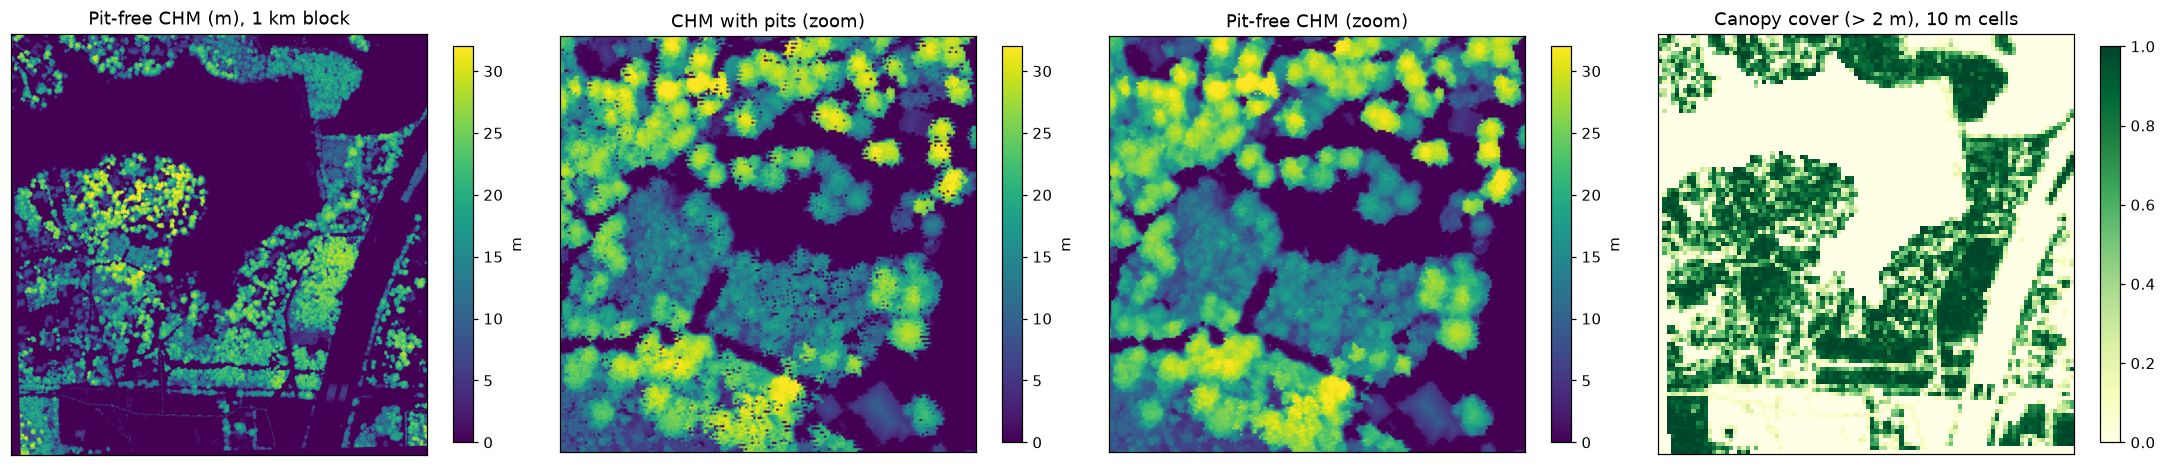

In [4]:
from scipy import ndimage as nd  # morphology

def mask_empty(grid, cloud, cells=2):  # set CHM cells with no return within `cells` cells to 0 (water, data gaps)
    hits = rs.lidar.rasterize(cloud, float(abs(grid.x[1] - grid.x[0])), stat="count", bounds=cloud.bbox)  # returns per cell
    near = nd.binary_dilation(hits.reindex_like(grid, method="nearest").fillna(0).values > 0, iterations=cells)  # near data
    return grid.where(near, 0)  # interpolated values far from any return become 0

t0 = time.perf_counter()  # start the timer
chm_raw = mask_empty(rs.lidar.chm(pc, res=1.0, pit_free=False), pc)  # CHM with pits
chm = mask_empty(rs.lidar.chm(pc, res=1.0, pit_free=True), pc)  # pit-free CHM (median filter)
print(f"two 1 m CHMs in {time.perf_counter() - t0:.1f} s | grid {chm.shape} | "  # summary line
      f"canopy > 2 m: {float((chm > 2).mean()):.1%} of the area")  # summary
first = pcn.first_returns()  # one return per pulse
cover = (rs.lidar.rasterize(first.filter(np.asarray(first["height"]) > 2), 10.0, stat="count", bounds=pcn.bbox)  # canopy hits
         / rs.lidar.rasterize(first, 10.0, stat="count", bounds=pcn.bbox)).fillna(0)  # / all first returns

tall = (chm > 10).coarsen(x=200, y=200, boundary="trim").mean()  # share of tall canopy in 200 m windows
wy, wx = np.unravel_index(int(tall.argmax()), tall.shape)  # the most forested window
zoom = dict(x=slice(wx * 200, wx * 200 + 200), y=slice(wy * 200, wy * 200 + 200))  # its pixel ranges
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))  # four panels
rs.viz.plot_raster(chm, ax=axes[0], cmap="viridis", vmin=0, vmax=32, title="Pit-free CHM (m), 1 km block")  # full CHM
rs.viz.plot_raster(chm_raw.isel(zoom), ax=axes[1], cmap="viridis", vmin=0, vmax=32, title="CHM with pits (zoom)")  # pits
rs.viz.plot_raster(chm.isel(zoom), ax=axes[2], cmap="viridis", vmin=0, vmax=32, title="Pit-free CHM (zoom)")  # filled
rs.viz.plot_raster(cover, ax=axes[3], cmap="YlGn", vmin=0, vmax=1, title="Canopy cover (> 2 m), 10 m cells")  # cover
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

## Area-based metrics on a grid

`rs.lidar.grid_metrics` computes height metrics per cell from the normalised points; `rs.lidar.structure_metrics` adds foliage height diversity, effective LAI and the canopy relief ratio. A 20 m cell (400 m²) matches a common field plot size.


area-based metrics for 2601 cells in 0.9 s


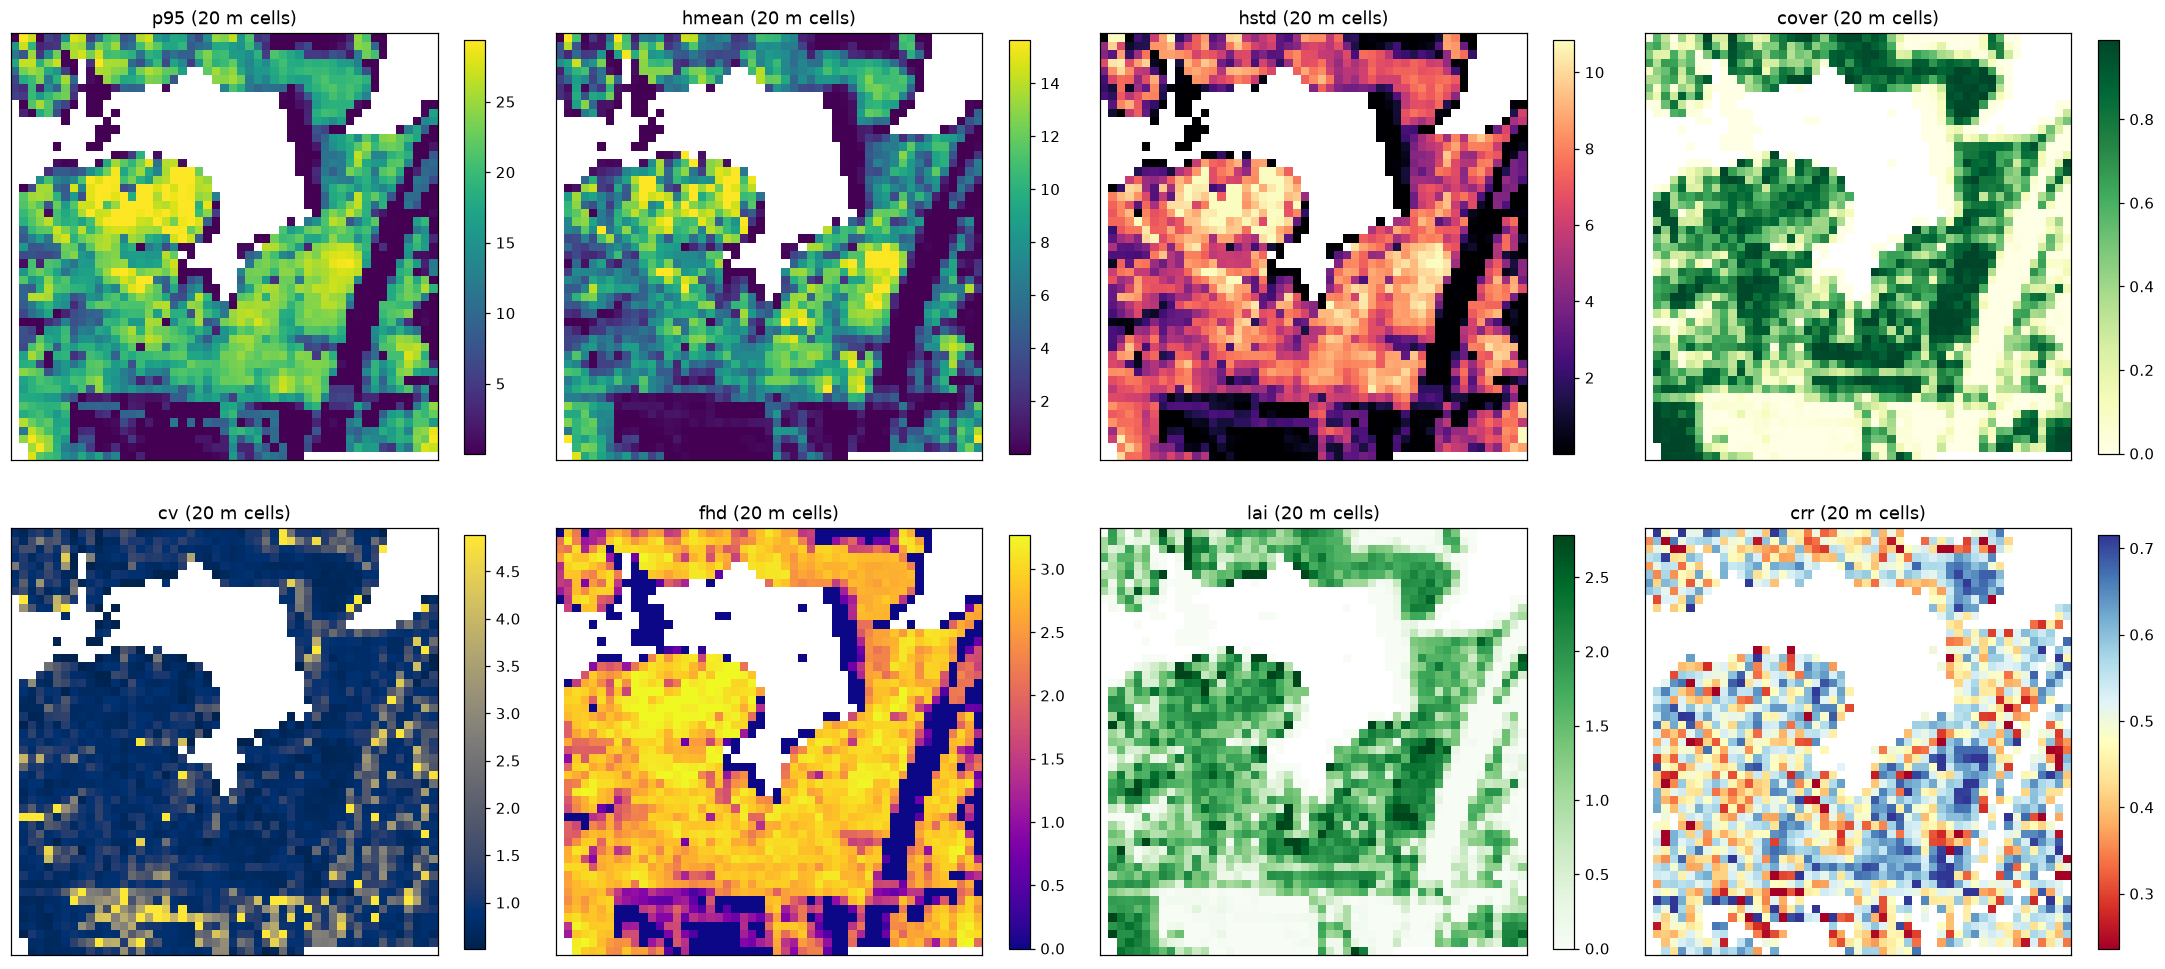

In [5]:
t0 = time.perf_counter()  # start the timer
# height metrics per 20 m cell
gm = rs.lidar.grid_metrics(pcn, res=20.0, metrics=("hmax", "hmean", "hstd", "p25", "p50", "p75", "p95", "cv", "cover",
                                                   "density"))  # height metrics per 20 m cell
sm = rs.lidar.structure_metrics(pcn, res=20.0)  # FHD, LAI and canopy relief ratio
print(f"area-based metrics for {gm.sizes['x'] * gm.sizes['y']} cells in {time.perf_counter() - t0:.1f} s")  # timing

fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))  # eight panels
# eight metric maps
for ax, (ds, k, cmap) in zip(axes.ravel(), [(gm, "p95", "viridis"), (gm, "hmean", "viridis"), (gm, "hstd", "magma"),
                                            (gm, "cover", "YlGn"), (gm, "cv", "cividis"), (sm, "fhd", "plasma"),
                                            (sm, "lai", "Greens"), (sm, "crr", "RdYlBu")]):  # eight metrics
    rs.viz.plot_raster(ds[k], ax=ax, cmap=cmap, title=f"{k} (20 m cells)")  # map
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

,hmax,hmean,hstd,p25,p50,p75,p95,cv,cover,density,fhd,lai,crr
mean,19.73,6.80,5.91,0.98,6.44,11.28,16.39,1.33,0.54,2.20,2.45,1.30,0.51
50%,21.57,6.82,6.41,0.05,5.79,11.85,18.17,0.92,0.58,2.15,2.76,1.37,0.52
max,36.24,19.42,13.55,16.08,24.43,29.21,33.85,10.71,1.00,6.30,3.44,13.82,0.84


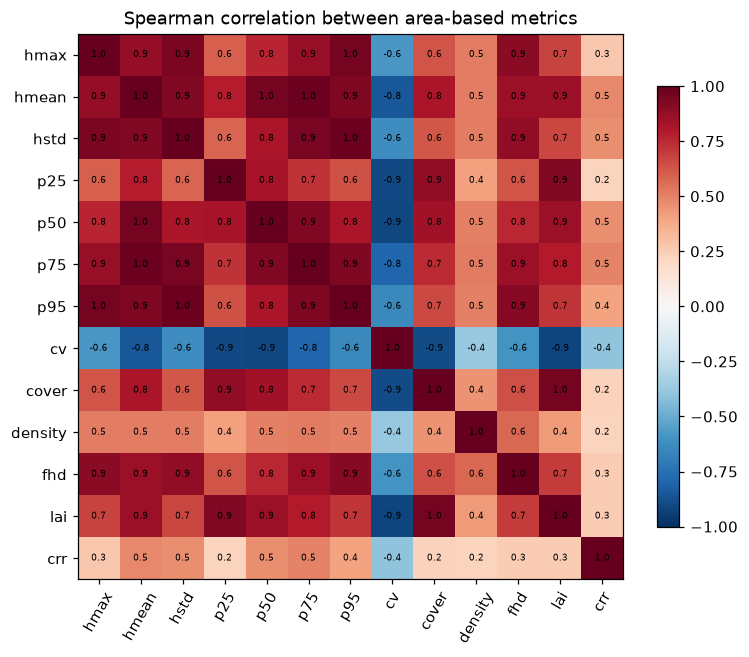

In [6]:
table = gm.to_dataframe().join(sm.to_dataframe(), rsuffix="_s")  # one row per cell
# keep the metric columns
table = table[[c for c in ("hmax", "hmean", "hstd", "p25", "p50", "p75", "p95", "cv", "cover", "density", "fhd", "lai", "crr")
               if c in table]].dropna()  # the metric columns
display(table.describe().loc[["mean", "50%", "max"]].round(2))  # summary
fig, ax = plt.subplots(figsize=(8, 6.5))  # one panel
corr = table.corr(method="spearman")  # rank correlations between metrics
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)  # heat map
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60)  # labels
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)  # labels
for i in range(len(corr)):  # each row
    for j in range(len(corr)):  # each column
        ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=6)  # value
plt.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Spearman correlation between area-based metrics"); plt.show()  # draw

The height metrics are strongly correlated with one another (one "height" dimension), while cover, the coefficient of variation and FHD carry partly independent information about canopy closure and layering. Regression models for biomass usually need one height metric and one cover or variability metric; using all of them invites overfitting.


## Vertical structure

`rs.lidar.height_profile` bins the returns by height and computes the gap fraction and the leaf area density (LAD) for each layer. The cell selects a tall closed forest stand and an open, low stand by their 20 m p95 values and compares their profiles; `rs.lidar.foliage_height_diversity` gives the FHD of each.


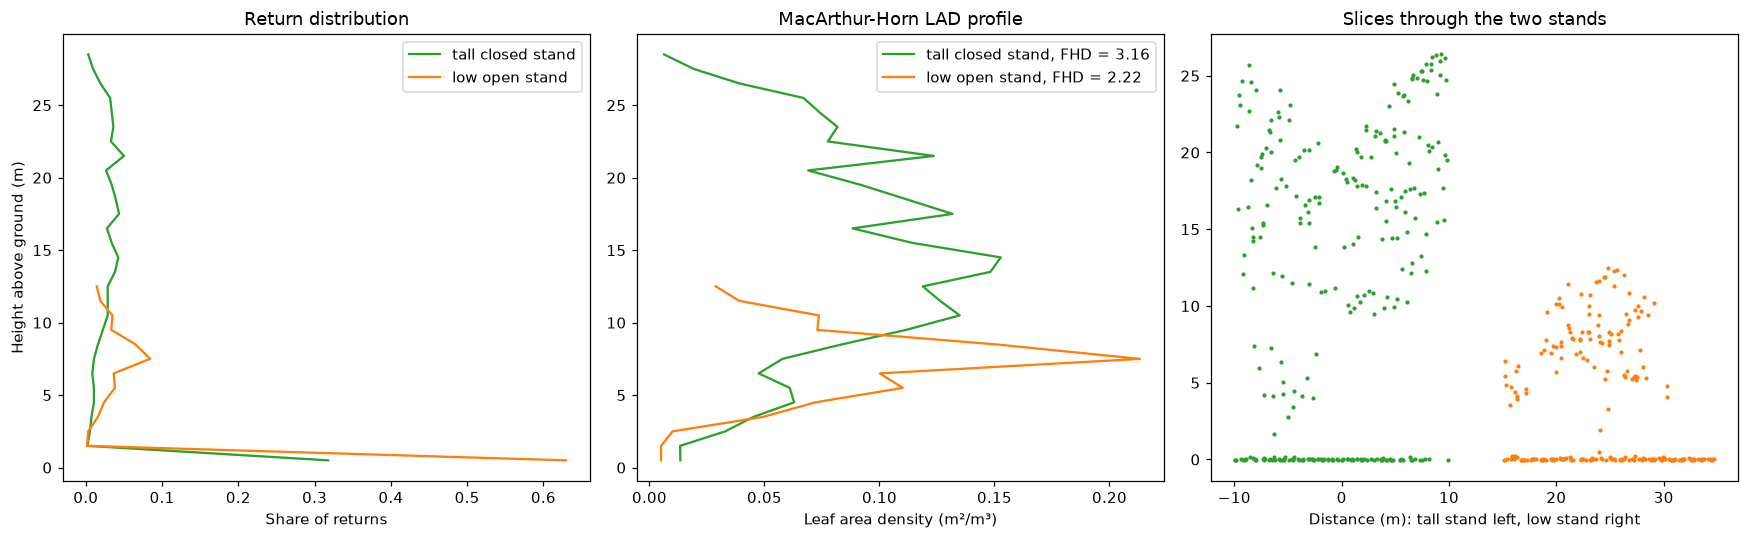

In [7]:
cells = table.reset_index()  # cell centres and metrics
bx0, by0, bx1, by1 = pcn.bbox  # block extent
cells = cells[(cells.x > bx0 + 10) & (cells.x < bx1 - 10) & (cells.y > by0 + 10) & (cells.y < by1 - 10)]  # whole cells only
tall = cells[(cells.p95 > 25) & (cells.cover > 0.8)].iloc[0]  # a tall closed stand
low = cells[(cells.p95 > 5) & (cells.p95 < 12) & (cells.cover > 0.3)].iloc[0]  # a low, open stand

def stand(c, size=20):  # points of one 20 m cell
    return pcn.crop(c.x - size / 2, c.y - size / 2, c.x + size / 2, c.y + size / 2)  # points within the cell

fig, axes = plt.subplots(1, 3, figsize=(16, 5))  # three panels
for (name, c), col in zip((("tall closed stand", tall), ("low open stand", low)), ("C2", "C1")):  # the two stands
    s = stand(c)  # its points
    prof = rs.lidar.height_profile(s, bin_size=1.0)  # vertical profile
    mid = (prof.z_bottom + prof.z_top) / 2  # layer centres
    axes[0].plot(prof.fraction, mid, color=col, label=name)  # share of returns per layer
    axes[1].plot(prof.lad, mid, color=col, label=f"{name}, FHD = {rs.lidar.foliage_height_diversity(s):.2f}")  # LAD
    sec = s.filter(np.abs(np.asarray(s.y) - c.y) < 3)  # a 6 m wide slice through the stand
    axes[2].scatter(np.asarray(sec.x) - c.x + (0 if col == "C2" else 25), sec["height"], s=3, color=col)  # profile view
axes[0].set(xlabel="Share of returns", ylabel="Height above ground (m)", title="Return distribution")  # labels
axes[1].set(xlabel="Leaf area density (m²/m³)", title="MacArthur-Horn LAD profile")  # labels
axes[2].set(xlabel="Distance (m): tall stand left, low stand right", title="Slices through the two stands")  # labels
for a in axes[:2]: a.legend()  # legends
plt.tight_layout(); plt.show()  # draw

## Metrics for field plots

Field inventories measure trees on plots, often circles of 11.28 m radius (400 m²). `rs.lidar.plot_metrics` computes the same metrics for the points inside each plot. Here 30 plot centres are placed at random in forested parts of the block; with field measurements of biomass or volume for these plots, the table would be the training data for an area-based model.


In [8]:
rng = np.random.default_rng(7)  # reproducible plot locations
forest = cells[cells.cover > 0.5].sample(30, random_state=7)  # 30 forested 20 m cells
plots = gpd.GeoDataFrame({"plot": np.arange(1, 31)},  # plot ids
                         geometry=gpd.points_from_xy(forest.x + rng.uniform(-4, 4, 30),  # jittered centres
                                                     forest.y + rng.uniform(-4, 4, 30)), crs=32615)
pm = rs.lidar.plot_metrics(pcn, plots, radius=11.28)  # metrics inside each 400 m² circle
pm.drop(columns="geometry").set_index("plot").round(2).head(10)  # the first ten plots

,hmax,hmean,hstd,p25,p50,p75,p95,cover,density,fhd,lai,crr,n_points
plot,,,,,,,,,,,,,
1,28.98,9.42,8.41,3.18,6.65,15.13,25.83,0.80,1.73,3.04,2.37,0.33,690
2,23.87,10.12,7.16,0.13,11.74,16.13,19.90,0.93,2.90,2.65,1.81,0.42,1159
3,24.75,10.40,8.84,0.11,11.16,18.38,22.76,0.69,2.14,2.62,1.61,0.42,854
4,14.31,4.01,3.74,0.07,4.13,6.95,10.26,0.70,1.88,2.07,1.29,0.28,749
5,20.77,7.08,7.21,0.09,3.65,13.43,19.63,0.61,1.92,2.51,1.39,0.34,768
6,29.51,12.43,9.74,3.86,11.74,20.91,27.94,0.97,2.57,3.05,2.20,0.42,1025
7,21.88,7.48,6.30,0.04,7.25,12.93,17.57,0.67,2.01,2.52,1.49,0.34,802
8,21.22,6.74,6.86,0.04,6.07,13.29,17.69,0.48,3.66,2.17,1.10,0.32,1462
9,18.65,5.99,5.95,0.03,5.50,12.05,15.16,0.43,3.37,2.12,0.94,0.32,1345


## Treetop detection

`rs.lidar.detect_trees` finds local maxima of the CHM above `min_height`. By default the search window grows with height ($3 + 0.08\,h$ m), so a 30 m tree needs about 5.4 m of separation from a taller neighbour; a fixed `window` uses the same distance everywhere. The table compares the two on the 1 m CHM and on a 0.5 m CHM.


In [9]:
chm05 = mask_empty(rs.lidar.chm(pc, res=0.5, pit_free=True), pc, cells=4)  # 0.5 m CHM
area_ha = float((chm > 2).sum()) / 1e4  # canopy area in hectares (1 m cells)
rows, tops_all = {}, {}  # results
# detection settings to compare
for name, grid, kw in (("variable window, 1 m CHM", chm, {}), ("fixed 3 m window, 1 m CHM", chm, {"window": 3}),
                       ("fixed 6 m window, 1 m CHM", chm, {"window": 6}), ("variable window, 0.5 m CHM", chm05, {})):  # settings
    t0 = time.perf_counter()  # start the timer
    tops = rs.lidar.detect_trees(grid, min_height=5, **kw)  # treetops
    tops_all[name] = tops  # keep them
    rows[name] = {"trees": len(tops), "trees per ha of canopy": len(tops) / area_ha,  # counts
                  "median height (m)": float(np.median(tops.height)), "seconds": time.perf_counter() - t0}
pd.DataFrame(rows).T.round(1)  # show the comparison

,trees,trees per ha of canopy,median height (m),seconds
"variable window, 1 m CHM",7448.0,184.1,14.6,0.1
"fixed 3 m window, 1 m CHM",10984.0,271.6,18.2,0.2
"fixed 6 m window, 1 m CHM",3412.0,84.4,20.3,0.1
"variable window, 0.5 m CHM",6964.0,172.2,16.3,0.7


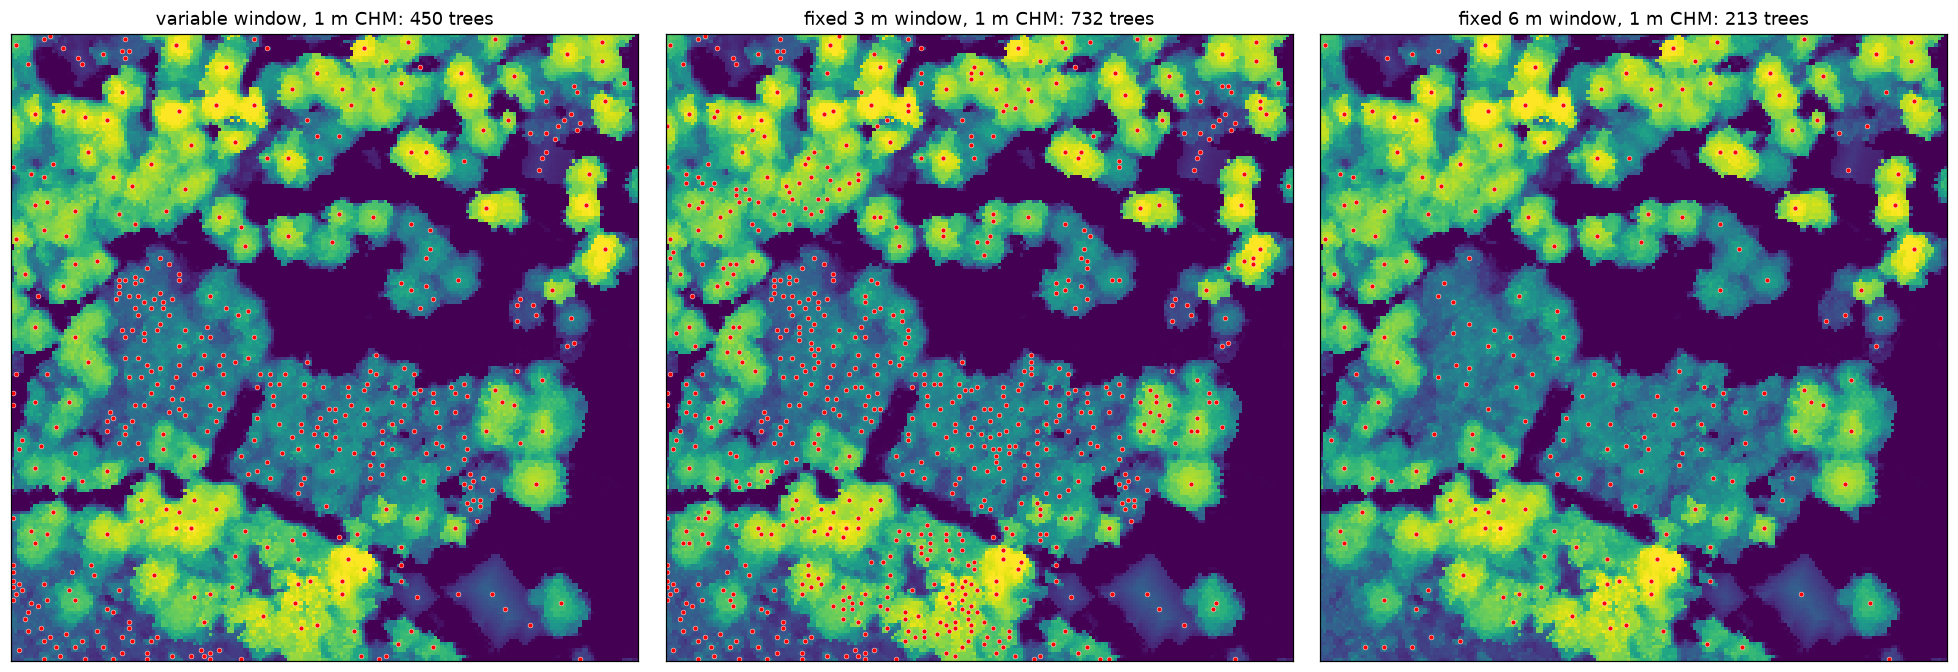

In [10]:
sub = chm.isel(zoom)  # the same 200 m forest window as above
xmin, xmax, ymin, ymax = float(sub.x.min()), float(sub.x.max()), float(sub.y.min()), float(sub.y.max())  # its extent
fig, axes = plt.subplots(1, 3, figsize=(18, 6))  # three panels
for ax, name in zip(axes, ("variable window, 1 m CHM", "fixed 3 m window, 1 m CHM", "fixed 6 m window, 1 m CHM")):  # settings
    rs.viz.plot_raster(sub, ax=ax, cmap="viridis", vmin=0, vmax=32, colorbar=False, title=name)  # CHM
    t = tops_all[name].cx[xmin:xmax, ymin:ymax]  # treetops in the window
    ax.scatter(t.geometry.x, t.geometry.y, s=10, c="red", edgecolor="white", linewidth=0.3)  # treetops
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{name}: {len(t)} trees")  # title with the count
plt.tight_layout(); plt.show()  # draw

A 3 m fixed window finds many maxima inside single large hardwood crowns (over-segmentation); a 6 m window merges neighbouring small pines (under-segmentation). The variable window is a compromise designed for conifers. Without field data to count real stems, the "right" setting cannot be known; ITD results should always be checked against field plots or very high resolution images.


## Crown segmentation and allometry

`rs.lidar.segment_crowns` grows a marker-controlled watershed from the treetops over the inverted CHM and returns a label raster and a GeoDataFrame of crown polygons with height, area and equivalent crown diameter $D = 2\sqrt{A/\pi}$.


7,448 crowns in 10.3 s | median area 29 m² | median diameter 6.1 m


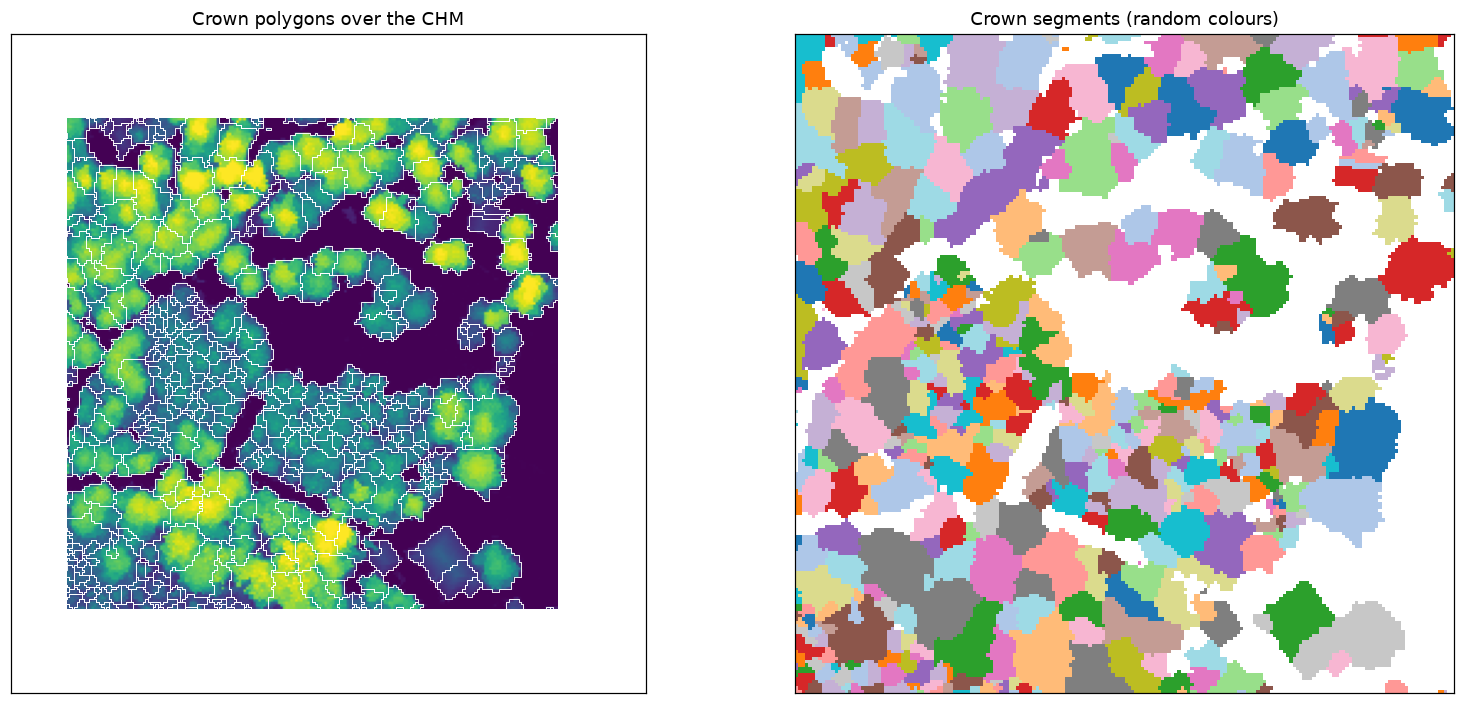

In [11]:
t0 = time.perf_counter()  # start the timer
tops = tops_all["variable window, 1 m CHM"]  # treetops from the default setting
labels, crowns = rs.lidar.segment_crowns(chm, tops, min_height=3)  # watershed crowns
# summary line
print(f"{len(crowns):,} crowns in {time.perf_counter() - t0:.1f} s | median area {crowns.area_m2.median():.0f} m² | "
      f"median diameter {crowns.diameter_m.median():.1f} m")  # summary

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))  # two panels
rs.viz.plot_raster(sub, ax=axes[0], cmap="viridis", vmin=0, vmax=32, colorbar=False, title="Crown polygons over the CHM")  # CHM
crowns.cx[xmin:xmax, ymin:ymax].boundary.plot(ax=axes[0], color="white", linewidth=0.6)  # crown outlines
lab = labels.isel(zoom).values  # zoomed labels
shuffled = np.r_[0, np.random.default_rng(0).permutation(int(labels.max())) + 1][lab]  # random colours per crown
axes[1].imshow(np.where(lab > 0, shuffled % 20, np.nan), cmap="tab20", interpolation="nearest")  # crown segments
axes[1].set_title("Crown segments (random colours)")  # title
for a in axes: a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

**Allometry.** Taller trees have wider crowns. A power law $D = a\,H^b$, fitted on log-transformed values, describes the relation; a crown that falls far from the curve is often a merged group of trees or a fragment of one. Allometric equations of this kind link LiDAR heights and crown sizes to stem diameter and biomass.


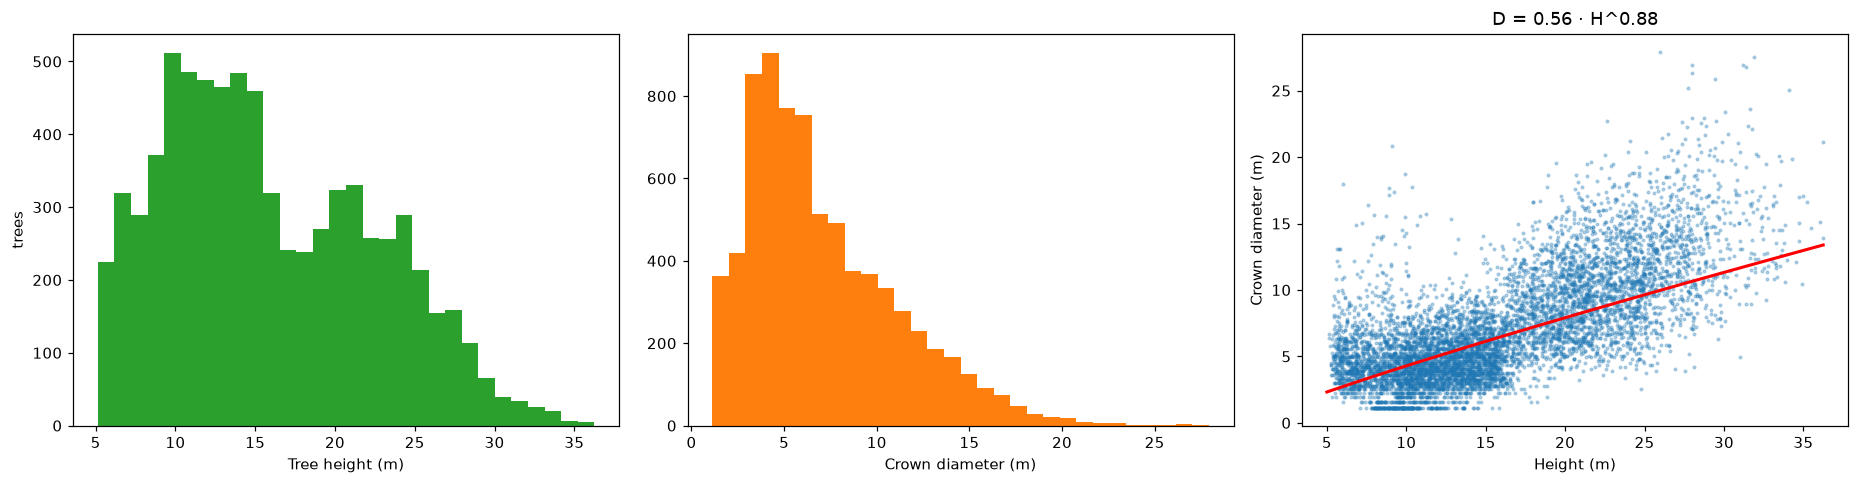

In [12]:
ok = (crowns.height > 5) & (crowns.diameter_m > 1)  # usable crowns
bfit, logafit = np.polyfit(np.log(crowns.height[ok]), np.log(crowns.diameter_m[ok]), 1)  # log D = log a + b log H
a_fit = np.exp(logafit)  # back-transformed coefficient
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))  # three panels
axes[0].hist(crowns.height[ok], bins=30, color="C2"); axes[0].set(xlabel="Tree height (m)", ylabel="trees")  # heights
axes[1].hist(crowns.diameter_m[ok], bins=30, color="C1"); axes[1].set(xlabel="Crown diameter (m)")  # diameters
axes[2].scatter(crowns.height[ok], crowns.diameter_m[ok], s=3, alpha=0.3)  # height vs diameter
hh = np.linspace(5, crowns.height.max(), 100)  # heights for the curve
axes[2].plot(hh, a_fit * hh ** bfit, "r-", lw=2)  # fitted power law
axes[2].set(xlabel="Height (m)", ylabel="Crown diameter (m)", title=f"D = {a_fit:.2f} · H^{bfit:.2f}")  # labels
plt.tight_layout(); plt.show()  # draw

## Point-based tree segmentation

`rs.lidar.segment_trees_points` assigns each vegetation point above 2 m to the treetop that is nearest relative to that tree's expected crown radius ($0.3\,h$, clipped to 1 to 12 m) and not lower than the point. It works directly in 3D, so points under the canopy surface (lower branches, understorey) can belong to a different tree than the CHM pixel above them. The cell compares the result with the raster crowns.


In [13]:
t0 = time.perf_counter()  # start the timer
pts_seg = rs.lidar.segment_trees_points(pcn, tops, min_height=2)  # tree_id from 3D assignment
pts_rast = rs.lidar.assign_points_to_crowns(pcn, labels)  # tree_id from the crown raster
print(f"point-based segmentation in {time.perf_counter() - t0:.1f} s")  # timing
tp = np.asarray(pts_seg["tree_id"]); tr = np.asarray(pts_rast["tree_id"])  # the two labelings
veg_pts = np.asarray(pcn["height"]) > 2  # vegetation points
both = veg_pts & (tp > 0) & (tr > 0)  # points labelled by both methods
pair = pd.DataFrame({"pt": tp[both], "rast": tr[both]})  # the two ids of each such point
purity = pair.groupby("pt").rast.agg(lambda v: v.value_counts().iloc[0] / len(v))  # share in the majority raster crown
# summary line
print(f"vegetation points assigned: point-based {np.mean(tp[veg_pts] > 0):.1%}, raster {np.mean(tr[veg_pts] > 0):.1%} | "
      f"median share of a point-based tree's points inside one raster crown: {purity.median():.1%}")  # comparison

point-based segmentation in 1.2 s


vegetation points assigned: point-based 85.5%, raster 98.6% | median share of a point-based tree's points inside one raster crown: 82.6%


## Point clouds of individual trees

With a `tree_id` on every point, each tree becomes its own small point cloud for per-tree analysis: height, crown base height (the lowest vegetation return), crown volume, intensity statistics for species classification. The cell views the six tallest trees in 3D and computes a few per-tree attributes.


,points,height,crown_base,mean_intensity,crown_length
count,4658.0,4658.0,4658.0,4658.0,4658.0
mean,131.0,19.6,5.7,17.6,13.9
50%,93.0,19.5,5.2,17.1,13.3
max,939.0,36.2,19.1,80.3,31.3


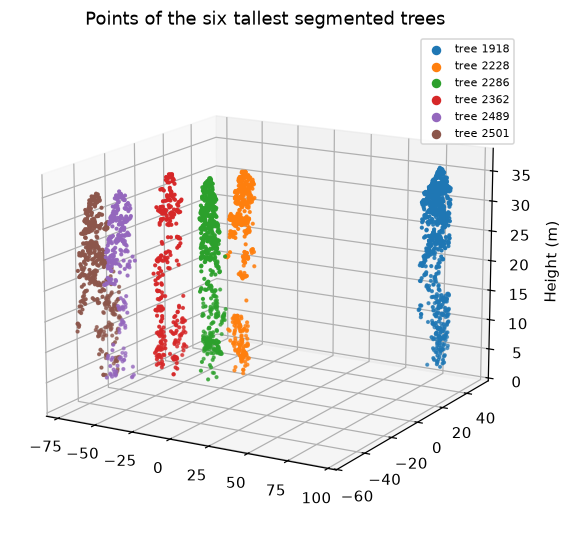

In [14]:
df = pts_seg.to_dataframe()  # points with tree_id and height
df = df[(df.tree_id > 0) & (df.height > 2)]  # vegetation points of segmented trees
per_tree = df.groupby("tree_id").agg(points=("height", "size"), height=("height", "max"),  # per-tree statistics
                                    crown_base=("height", lambda v: np.percentile(v, 5)),
                                    mean_intensity=("intensity", "mean"))
per_tree["crown_length"] = per_tree.height - per_tree.crown_base  # length of the live crown
display(per_tree[per_tree.points >= 30].describe().loc[["count", "mean", "50%", "max"]].round(1))  # summary

top6 = per_tree[per_tree.points >= 30].nlargest(6, "height").index  # the six tallest trees
s = df[df.tree_id.isin(top6)]  # their points
fig = plt.figure(figsize=(10, 6)); ax = fig.add_subplot(projection="3d")  # 3D axes
for k, (tid, g) in enumerate(s.groupby("tree_id")):  # each tree
    ax.scatter(g.x - s.x.mean(), g.y - s.y.mean(), g.height, s=3, color=plt.cm.tab10(k), label=f"tree {tid}")  # its points
ax.set(zlabel="Height (m)", title="Points of the six tallest segmented trees"); ax.view_init(15, -60)  # labels and angle
ax.legend(fontsize=7, markerscale=3); plt.show()  # draw

## Effect of point density

The Madison survey has about 1.7 points/m², often only a handful of returns per crown. The 2020 Ithaca survey has about 6.5 points/m². The cell takes the most forested 400 m block of an Ithaca tile, builds its DEM and CHM, and then thins the same points randomly to the Madison density to see what changes.


,points,trees detected,mean CHM (m),mean p95 (m),mean cover
Ithaca full (10.2 pts/m²),1626851.0,3100.0,15.26,21.44,0.64
Ithaca thinned (1.7 pts/m²),271997.0,4341.0,11.71,21.42,0.64


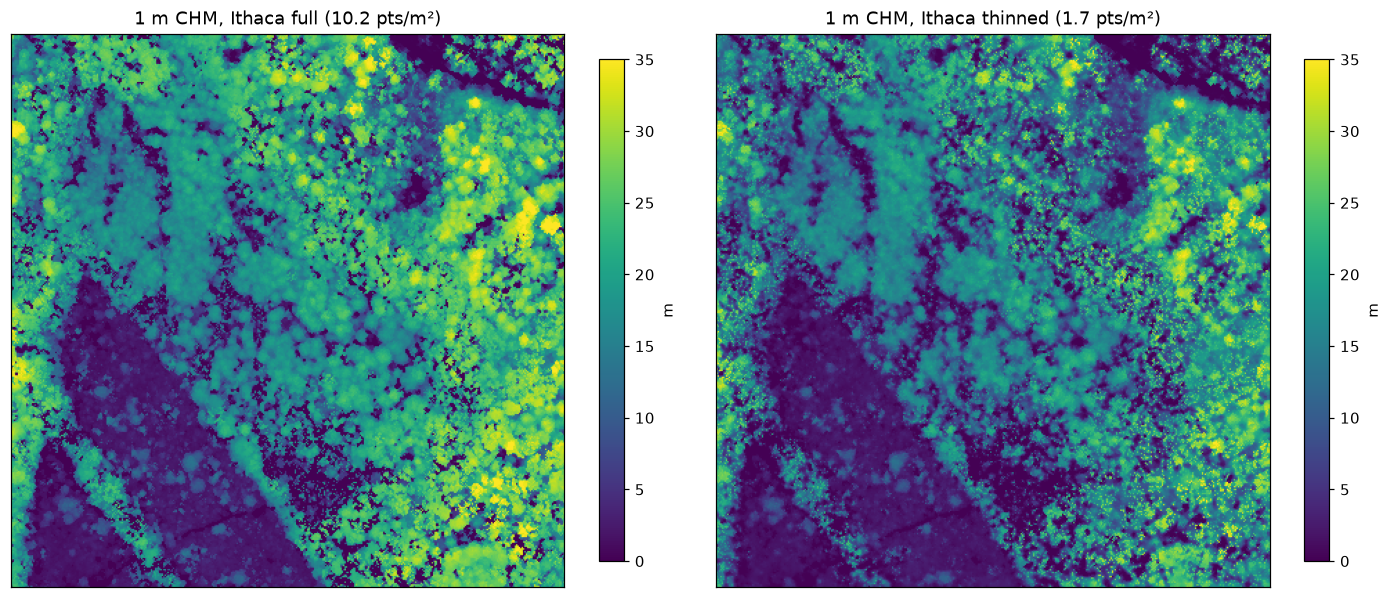

In [15]:
ith = rs.lidar.read_las(ITHACA_TILE).drop_noise()  # one Ithaca tile (ground classified)
chm5 = rs.lidar.chm(ith, res=5.0)  # coarse CHM to find forest
frac = (chm5 > 10).coarsen(x=80, y=80, boundary="trim").mean()  # share of tall canopy in 400 m blocks
iy, ix = np.unravel_index(int(frac.argmax()), frac.shape)  # the most forested block
bx, by = float(chm5.x[ix * 80]) - 2.5, float(chm5.y[iy * 80 + 79]) - 2.5  # its south-west corner
ith_blk = ith.crop(bx, by, bx + 400, by + 400)  # the 400 m block
dens = rs.lidar.summary(ith_blk)["density_pts_m2"]  # its density
thinned = rs.lidar.thin(ith_blk, method="random", fraction=1.7 / dens)  # thinned to the Madison density

rows, chms = {}, {}  # results
for name, cloud in ((f"Ithaca full ({dens:.1f} pts/m²)", ith_blk), ("Ithaca thinned (1.7 pts/m²)", thinned)):  # two densities
    d = rs.lidar.dem(ith_blk, 1.0)  # same DEM for both (from the full ground points)
    cn = rs.lidar.normalize_heights(cloud, d)  # heights
    c = mask_empty(rs.lidar.chm(rs.lidar.dsm(cloud, 1.0, bounds=ith_blk.bbox).reindex_like(d, method="nearest"), d), cloud)  # CHM
    chms[name] = c  # keep it
    t = rs.lidar.detect_trees(c, min_height=5)  # treetops
    g = rs.lidar.grid_metrics(cn, res=20.0, metrics=("p95", "cover"))  # area-based metrics
    rows[name] = {"points": len(cloud), "trees detected": len(t), "mean CHM (m)": float(c.mean()),  # results
                  "mean p95 (m)": float(g.p95.mean()), "mean cover": float(g.cover.mean())}
display(pd.DataFrame(rows).T.round(2))  # comparison table

fig, axes = plt.subplots(1, 2, figsize=(13, 6))  # two panels
for ax, (name, c) in zip(axes, chms.items()):  # the two CHMs
    rs.viz.plot_raster(c, ax=ax, cmap="viridis", vmin=0, vmax=35, title=f"1 m CHM, {name}")  # map
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # draw

Area-based metrics such as p95 and cover hardly change with thinning: they summarise dozens to hundreds of returns per 20 m cell either way. The CHM and tree detection change a lot. At the lower density most 1 m cells contain no return near a crown top, so the DSM is interpolated between a few scattered hits: it is several metres lower on average and bumpy, and the bumps become spurious local maxima, so *more* "trees" are detected, not fewer. Individual tree methods need dense data (and a CHM cell size matched to the point spacing); area-based methods work with sparse national surveys. (The Ithaca survey was flown in spring, so deciduous crowns may be partly leaf-off; this affects cover in both versions equally.)


## Exporting the products

Crowns and treetops go to a GeoPackage, the CHM and metric grids to Cloud-Optimized GeoTIFFs, and the segmented point cloud (with `tree_id`) to LAZ.


In [16]:
gpkg = OUT / "madison_trees.gpkg"  # vector output
crowns.to_file(gpkg, layer="crowns", driver="GPKG")  # crown polygons
tops.to_file(gpkg, layer="treetops", driver="GPKG")  # treetop points
pm.to_file(gpkg, layer="plots", driver="GPKG")  # plot metrics
rs.write(chm.astype("float32"), OUT / "madison_chm_1m_pitfree.tif")  # CHM
rs.write(gm.astype("float32"), OUT / "madison_grid_metrics_20m.tif")  # area-based metrics (one band per metric)
rs.lidar.write_las(pts_seg, OUT / "madison_trees_segmented.laz")  # points with tree_id
# list the files written
for p in (gpkg, OUT / "madison_chm_1m_pitfree.tif", OUT / "madison_grid_metrics_20m.tif", OUT / "madison_trees_segmented.laz"):
    print(f"{p.name:34s} {p.stat().st_size / 1e6:6.1f} MB")  # name and size

madison_trees.gpkg                    5.1 MB
madison_chm_1m_pitfree.tif            2.5 MB
madison_grid_metrics_20m.tif          0.1 MB
madison_trees_segmented.laz          11.1 MB


## Summary and exercises

**Key points**

- Every forest metric starts from heights above ground; check that few returns fall below the DEM.
- Pit-free CHMs give cleaner crowns; canopy cover is the share of first returns above a height threshold.
- Area-based metrics (percentile heights, cover, variability, FHD, LAI) summarise each cell or plot; with field plots they become predictors in biomass and volume models. Many height metrics are redundant.
- Height profiles and LAD describe the vertical layering that optical images cannot see.
- Treetop detection depends on the search window: fixed small windows over-segment broad crowns, large windows merge small trees; variable windows scale with height.
- Watershed crowns and point-based segmentation give per-tree heights, crown sizes and point clouds; allometry checks them and links them to biomass.
- Individual-tree methods need dense data; area-based metrics remain stable at low density.

**`geolattice.rsense` functions used:** `rs.lidar.read_las`, `rs.lidar.dem`, `rs.lidar.dsm`, `rs.lidar.chm`, `rs.lidar.normalize_heights`, `rs.lidar.classify_vegetation`, `rs.lidar.rasterize`, `rs.lidar.grid_metrics`, `rs.lidar.structure_metrics`, `rs.lidar.height_profile`, `rs.lidar.foliage_height_diversity`, `rs.lidar.plot_metrics`, `rs.lidar.detect_trees`, `rs.lidar.segment_crowns`, `rs.lidar.segment_trees_points`, `rs.lidar.assign_points_to_crowns`, `rs.lidar.thin`, `rs.lidar.summary`, `rs.lidar.write_las`, `rs.write`, `rs.viz.plot_raster`.

**Exercises**

1. Compute grid metrics at 10, 20 and 40 m. How do the mean and spread of p95 and cover change with cell size?
2. Change the cover height threshold from 2 m to 5 m. Which areas lose most cover?
3. Fit the crown allometry separately for trees below and above 20 m. Is one power law enough?
4. Run `detect_trees` with `smooth_sigma` 0, 0.5 and 1.5 on the 0.5 m CHM. How does the tree count change?
5. Thin the Ithaca block to 4, 2 and 1 points/m² and plot the number of detected trees against density.
